<a href="https://colab.research.google.com/github/KosarZarean/samsung-a57-digikala-reviews/blob/main/Design%20and%20Analysis%20of%20an%20OOD%20Scenario%20in%20Medical%20Diagnosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch torchvision scikit-learn pillow numpy

In [2]:
!pip install kaggle
# سپس فایل kaggle.json خود را آپلود کنید (از تنظیمات اکانت Kaggle دریافت کنید)
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia
!unzip chest-xray-pneumonia.zip -d ./chest_xray_data

Streaming output truncated to the last 5000 lines.
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: ./chest_xray_data/chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: ./chest_xra

In [3]:
import os
print(os.listdir("./chest_xray_data"))

['chest_xray']


In [4]:
print(os.listdir("./chest_xray_data/chest_xray"))

['train', '__MACOSX', 'chest_xray', 'val', 'test']


In [7]:
"""
OOD Scenario: Pneumonia detection — Hospital A (train) vs Hospital B (OOD test).
Ablation Study:
  1. Baseline            : fixed marker (top-left), no fix
  2. Proposed-Fixed      : fixed marker (top-left), with cue removal
  3. Proposed-Random     : random marker (4 corners), with cue removal
(Colab-ready — no argparse)
"""
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms as T
from PIL import Image, ImageDraw, ImageEnhance, ImageOps
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

# ============================================================
# setting
# ============================================================
DATA_DIR = "./chest_xray_data/chest_xray"
EPOCHS   = 5
BATCH    = 32
N_TRAIN  = 1000
N_TEST   = 234
# ============================================================

NORMAL, PNEUMONIA = 0, 1
BASE_SIZE = 256
MARKER_TEXT = "PORT"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


# ----------------------------------------------------------------------------
# 1) Marker (spurious cue)
# ----------------------------------------------------------------------------
def add_marker_fixed(img, rng):
    """Marker always in top-left corner (original scenario)."""
    img = img.copy()
    d = ImageDraw.Draw(img)
    w, h = img.size
    x = int(rng.uniform(0.02, 0.07) * w)
    y = int(rng.uniform(0.02, 0.07) * h)
    d.rectangle([x, y, x + int(0.17 * w), y + int(0.07 * h)], fill=255)
    d.text((x + 4, y + 4), MARKER_TEXT, fill=0)
    return img


def add_marker_random(img, rng):
    """Marker randomly placed in one of the 4 corners (realistic scenario)."""
    img = img.copy()
    d = ImageDraw.Draw(img)
    w, h = img.size
    bw = int(0.17 * w)
    bh = int(0.07 * h)
    corner = rng.choice(["TL", "TR", "BL", "BR"])
    if corner == "TL":
        x, y = int(rng.uniform(0.02, 0.07) * w), int(rng.uniform(0.02, 0.07) * h)
    elif corner == "TR":
        x, y = w - bw - int(rng.uniform(0.02, 0.07) * w), int(rng.uniform(0.02, 0.07) * h)
    elif corner == "BL":
        x, y = int(rng.uniform(0.02, 0.07) * w), h - bh - int(rng.uniform(0.02, 0.07) * h)
    else:
        x, y = w - bw - int(rng.uniform(0.02, 0.07) * w), h - bh - int(rng.uniform(0.02, 0.07) * h)
    d.rectangle([x, y, x + bw, y + bh], fill=255)
    d.text((x + 4, y + 4), MARKER_TEXT, fill=0)
    return img


# ----------------------------------------------------------------------------
# 2) Hospital simulations
# ----------------------------------------------------------------------------
def hospital_A(img, label, rng, marker_fn):
    img = img.resize((BASE_SIZE, BASE_SIZE))
    p = 0.9 if label == PNEUMONIA else 0.1
    return marker_fn(img, rng) if rng.random() < p else img


def hospital_B(img, label, rng, marker_fn):
    img = img.resize((BASE_SIZE, BASE_SIZE))
    img = img.resize((BASE_SIZE // 2, BASE_SIZE // 2)).resize((BASE_SIZE, BASE_SIZE))
    img = ImageEnhance.Contrast(img).enhance(rng.uniform(0.45, 0.65))
    img = ImageEnhance.Brightness(img).enhance(rng.uniform(1.25, 1.5))
    arr = np.asarray(img, dtype=np.float32)
    arr += np.random.RandomState(rng.randint(0, 10**6)).normal(0, 8, arr.shape)
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    p = 0.1 if label == PNEUMONIA else 0.9
    return marker_fn(img, rng) if rng.random() < p else img


def balanced_samples(samples, n_per_class, seed):
    rng = random.Random(seed)
    out = []
    for c in (NORMAL, PNEUMONIA):
        items = [s for s in samples if s[1] == c]
        rng.shuffle(items)
        out += items[:n_per_class]
    rng.shuffle(out)
    return out


def build_domain_images(samples, hospital_fn, marker_fn, seed):
    rng = random.Random(seed)
    imgs, labels = [], []
    for path, y in samples:
        img = Image.open(path).convert("L")
        imgs.append(hospital_fn(img, y, rng, marker_fn))
        labels.append(y)
    return imgs, labels


class XrayDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.imgs, self.labels, self.transform = imgs, labels, transform
    def __len__(self):
        return len(self.imgs)
    def __getitem__(self, i):
        return self.transform(self.imgs[i].convert("RGB")), self.labels[i]


# ----------------------------------------------------------------------------
# 3) Transforms
# ----------------------------------------------------------------------------
class CornerMask:
    """Black out all 4 corners."""
    def __init__(self, frac=0.28):
        self.frac = frac
    def __call__(self, img):
        img = img.copy()
        w, h = img.size
        cw, ch = int(w * self.frac), int(h * self.frac)
        d = ImageDraw.Draw(img)
        for box in [(0, 0, cw, ch), (w - cw, 0, w, ch), (0, h - ch, cw, h), (w - cw, h - ch, w, h)]:
            d.rectangle(box, fill=(0, 0, 0))
        return img


NORM = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

baseline_train_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), NORM])
baseline_eval_tf = baseline_train_tf

fixed_steps = [CornerMask(0.28), T.Lambda(lambda im: ImageOps.equalize(im))]

proposed_train_tf = T.Compose(fixed_steps + [
    T.RandomResizedCrop(224, scale=(0.8, 1.0)),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.5, contrast=0.5),
    T.RandomApply([T.GaussianBlur(5, (0.1, 2.0))], p=0.3),
    T.ToTensor(), NORM,
    T.RandomErasing(p=0.7, scale=(0.02, 0.10), value=0),
])
proposed_eval_tf = T.Compose(fixed_steps + [T.Resize((224, 224)), T.ToTensor(), NORM])


# ----------------------------------------------------------------------------
# 4) Model / training / evaluation
# ----------------------------------------------------------------------------
def make_model():
    m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    m.fc = nn.Linear(m.fc.in_features, 2)
    return m.to(DEVICE)


def train(model, loader, epochs, lr=1e-4):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        model.train(); total, correct, loss_sum = 0, 0, 0.0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            out = model(x); loss = crit(out, y)
            loss.backward(); opt.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item(); total += len(y)
        print(f"  epoch {ep + 1}/{epochs}  loss={loss_sum / total:.4f}  train_acc={correct / total:.3f}")


@torch.no_grad()
def evaluate(model, loader):
    model.eval(); ys, preds, probs = [], [], []
    for x, y in loader:
        p = torch.softmax(model(x.to(DEVICE)), 1)[:, 1].cpu()
        probs += p.tolist(); preds += (p > 0.5).int().tolist(); ys += y.tolist()
    return dict(acc=accuracy_score(ys, preds),
                sensitivity=recall_score(ys, preds, pos_label=PNEUMONIA),
                specificity=recall_score(ys, preds, pos_label=NORMAL),
                f1=f1_score(ys, preds), auc=roc_auc_score(ys, probs))


def fmt(name, r):
    return (f"{name:<34} acc={r['acc']:.3f}  sens={r['sensitivity']:.3f}  "
            f"spec={r['specificity']:.3f}  F1={r['f1']:.3f}  AUC={r['auc']:.3f}")


# ----------------------------------------------------------------------------
# 5) Run one experiment (given marker type + transforms)
# ----------------------------------------------------------------------------
def run_experiment(tag, marker_fn, tr_tf, ev_tf, train_s, test_s):
    print(f"\n{'='*60}\n  EXPERIMENT: {tag}\n{'='*60}")
    set_seed(42)

    A_tr_imgs, A_tr_y = build_domain_images(train_s, hospital_A, marker_fn, seed=10)
    A_te_imgs, A_te_y = build_domain_images(test_s, hospital_A, marker_fn, seed=11)
    B_te_imgs, B_te_y = build_domain_images(test_s, hospital_B, marker_fn, seed=12)

    model = make_model()
    train_loader = DataLoader(XrayDataset(A_tr_imgs, A_tr_y, tr_tf),
                              batch_size=BATCH, shuffle=True, num_workers=2)
    train(model, train_loader, EPOCHS)

    id_loader  = DataLoader(XrayDataset(A_te_imgs, A_te_y, ev_tf), batch_size=64)
    ood_loader = DataLoader(XrayDataset(B_te_imgs, B_te_y, ev_tf), batch_size=64)
    return evaluate(model, id_loader), evaluate(model, ood_loader)


# ----------------------------------------------------------------------------
# 6) Main — run all three experiments
# ----------------------------------------------------------------------------
def main():
    print(f"Loading dataset from: {DATA_DIR}")
    tr = datasets.ImageFolder(f"{DATA_DIR}/train")
    te = datasets.ImageFolder(f"{DATA_DIR}/test")
    print("classes:", tr.class_to_idx)

    train_s = balanced_samples(tr.samples, N_TRAIN, 1)
    test_s  = balanced_samples(te.samples, N_TEST, 2)

    experiments = [
        ("Baseline (fixed marker, no fix)",
         add_marker_fixed, baseline_train_tf, baseline_eval_tf),
        ("Proposed-Fixed (fixed marker)",
         add_marker_fixed, proposed_train_tf, proposed_eval_tf),
        ("Proposed-Random (random marker)",
         add_marker_random, proposed_train_tf, proposed_eval_tf),
    ]

    results = []
    for tag, marker_fn, tr_tf, ev_tf in experiments:
        r_id, r_ood = run_experiment(tag, marker_fn, tr_tf, ev_tf, train_s, test_s)
        results.append((tag, r_id, r_ood))

    # ---------- Final summary ----------
    print("\n\n" + "="*90)
    print("FINAL RESULTS — ABLATION STUDY")
    print("="*90)
    for tag, r_id, r_ood in results:
        print(f"\n[{tag}]")
        print("  " + fmt("  ID (Hospital A)", r_id))
        print("  " + fmt("  OOD (Hospital B)", r_ood))
        print(f"    accuracy drop: {(r_id['acc'] - r_ood['acc']) * 100:.1f} points")

    # ---------- Markdown table (for the report) ----------
    print("\n\n" + "="*90)
    print("MARKDOWN TABLE (copy into report)")
    print("="*90)
    header = "| مدل | دقت ID | دقت OOD | افت دقت | حساسیت OOD | AUC در OOD |"
    sep    = "|:---|:---:|:---:|:---:|:---:|:---:|"
    print(header)
    print(sep)
    for tag, r_id, r_ood in results:
        drop = (r_id['acc'] - r_ood['acc']) * 100
        print(f"| {tag} | {r_id['acc']*100:.1f}% | {r_ood['acc']*100:.1f}% | "
              f"{drop:.1f} | {r_ood['sensitivity']*100:.1f}% | {r_ood['auc']:.3f} |")


main()

Device: cuda
Loading dataset from: ./chest_xray_data/chest_xray
classes: {'NORMAL': 0, 'PNEUMONIA': 1}

  EXPERIMENT: Baseline (fixed marker, no fix)
  epoch 1/5  loss=0.0875  train_acc=0.970
  epoch 2/5  loss=0.0162  train_acc=0.995
  epoch 3/5  loss=0.0123  train_acc=0.997
  epoch 4/5  loss=0.0095  train_acc=0.996
  epoch 5/5  loss=0.0039  train_acc=0.999

  EXPERIMENT: Proposed-Fixed (fixed marker)
  epoch 1/5  loss=0.3083  train_acc=0.863
  epoch 2/5  loss=0.1873  train_acc=0.927
  epoch 3/5  loss=0.1537  train_acc=0.939
  epoch 4/5  loss=0.1406  train_acc=0.947
  epoch 5/5  loss=0.1331  train_acc=0.952

  EXPERIMENT: Proposed-Random (random marker)
  epoch 1/5  loss=0.3094  train_acc=0.866
  epoch 2/5  loss=0.1863  train_acc=0.929
  epoch 3/5  loss=0.1592  train_acc=0.938
  epoch 4/5  loss=0.1353  train_acc=0.944
  epoch 5/5  loss=0.1310  train_acc=0.953


FINAL RESULTS — ABLATION STUDY

[Baseline (fixed marker, no fix)]
    ID (Hospital A)                  acc=0.919  sens=0.987  

In [9]:
# ============================================================
# Ablation Study: M1=Baseline, M2=CornerMask, M3=Equalization, M4=Full
# (Self-contained — loads data itself)
# ============================================================
import torch
from torchvision import datasets, transforms as T
from torch.utils.data import DataLoader
from PIL import ImageOps

# ---------- 1) setting upload dataset----------
print(f"Loading dataset from: {DATA_DIR}")
tr = datasets.ImageFolder(f"{DATA_DIR}/train")
te = datasets.ImageFolder(f"{DATA_DIR}/test")

train_s = balanced_samples(tr.samples, N_TRAIN, 1)
test_s  = balanced_samples(te.samples, N_TEST, 2)
print(f"Train samples: {len(train_s)} | Test samples: {len(test_s)}")

# ---------- 2) تعریف transformهای جداگانه برای هر مدل ----------
tf_baseline = T.Compose([T.Resize((224,224)), T.ToTensor(), NORM])

tf_corner_only = T.Compose([
    CornerMask(0.28),
    T.Resize((224,224)), T.ToTensor(), NORM
])

tf_equalize_only = T.Compose([
    T.Lambda(lambda im: ImageOps.equalize(im)),
    T.Resize((224,224)), T.ToTensor(), NORM
])

tf_full = proposed_train_tf   # (CornerMask + Equalize + Augmentation)

# ---------- 3)RUN 4 MODEL ----------
ablation_configs = [
    ("M1: Baseline",           tf_baseline),
    ("M2: +CornerMask",        tf_corner_only),
    ("M3: +Equalization",      tf_equalize_only),
    ("M4: Full (Proposed)",    tf_full),
]

ablation_results = []
for tag, tf in ablation_configs:
    print(f"\n{'='*60}\n  {tag}\n{'='*60}")
    set_seed(42)
    r_id, r_ood = run_experiment(tag, add_marker_fixed, tf, tf, train_s, test_s)
    ablation_results.append((tag, r_id, r_ood))
    print(f"  ID acc={r_id['acc']:.3f} | OOD acc={r_ood['acc']:.3f} | OOD AUC={r_ood['auc']:.3f}")

# ---------- 4)final table ----------
print("\n\n" + "="*80)
print("ABLATION RESULTS — COMPONENT CONTRIBUTION")
print("="*80)
print("\n| مدل | دقت ID | دقت OOD | افت دقت | ویژگی OOD | AUC OOD |")
print("|:---|:---:|:---:|:---:|:---:|:---:|")
for tag, r_id, r_ood in ablation_results:
    drop = (r_id['acc'] - r_ood['acc']) * 100
    print(f"| {tag} | {r_id['acc']*100:.1f}% | {r_ood['acc']*100:.1f}% | "
          f"{drop:.1f} | {r_ood['specificity']*100:.1f}% | {r_ood['auc']:.3f} |")

Loading dataset from: ./chest_xray_data/chest_xray
Train samples: 2000 | Test samples: 468

  M1: Baseline

  EXPERIMENT: M1: Baseline
  epoch 1/5  loss=0.0875  train_acc=0.971
  epoch 2/5  loss=0.0148  train_acc=0.995
  epoch 3/5  loss=0.0091  train_acc=0.997
  epoch 4/5  loss=0.0073  train_acc=0.999
  epoch 5/5  loss=0.0025  train_acc=1.000
  ID acc=0.902 | OOD acc=0.511 | OOD AUC=0.494

  M2: +CornerMask

  EXPERIMENT: M2: +CornerMask
  epoch 1/5  loss=0.1316  train_acc=0.954
  epoch 2/5  loss=0.0326  train_acc=0.991
  epoch 3/5  loss=0.0186  train_acc=0.995
  epoch 4/5  loss=0.0197  train_acc=0.993
  epoch 5/5  loss=0.0047  train_acc=0.999
  ID acc=0.833 | OOD acc=0.545 | OOD AUC=0.909

  M3: +Equalization

  EXPERIMENT: M3: +Equalization
  epoch 1/5  loss=0.0901  train_acc=0.968
  epoch 2/5  loss=0.0198  train_acc=0.996
  epoch 3/5  loss=0.0114  train_acc=0.997
  epoch 4/5  loss=0.0064  train_acc=0.998
  epoch 5/5  loss=0.0033  train_acc=1.000
  ID acc=0.917 | OOD acc=0.530 | OOD 

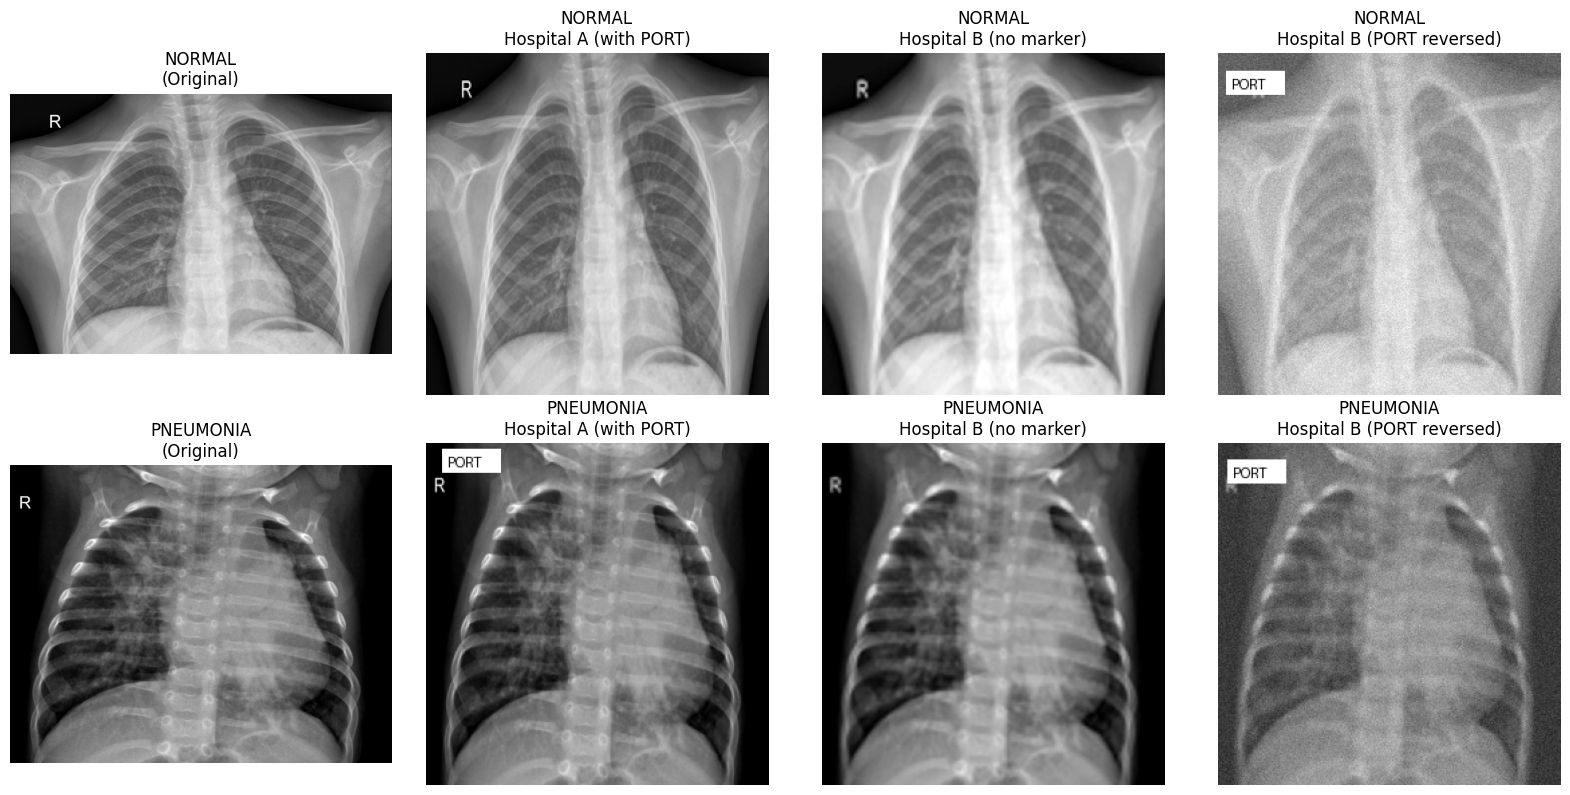

Saved: fig1_samples.png


In [10]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import random

# یک تصویر نمونه از هر کلاس بردارید
sample_normal = [s for s in test_s if s[1] == NORMAL][0][0]
sample_pneu   = [s for s in test_s if s[1] == PNEUMONIA][0][0]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
rng = random.Random(42)

for row, (path, label, name) in enumerate([
    (sample_normal, NORMAL, "NORMAL"),
    (sample_pneu, PNEUMONIA, "PNEUMONIA"),
]):
    img = Image.open(path).convert("L")

    # 1) اصلی
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"{name}\n(Original)")
    axes[row, 0].axis("off")

    # 2) بیمارستان A (با برچسب)
    imgA = hospital_A(img, label, rng, add_marker_fixed)
    axes[row, 1].imshow(imgA, cmap="gray")
    axes[row, 1].set_title(f"{name}\nHospital A (with PORT)")
    axes[row, 1].axis("off")

    # 3) بیمارستان B (بدون برچسب، فقط تغییر ظاهری)
    imgB_no_marker = img.resize((BASE_SIZE, BASE_SIZE))
    imgB_no_marker = imgB_no_marker.resize((BASE_SIZE//2, BASE_SIZE//2)).resize((BASE_SIZE, BASE_SIZE))
    from PIL import ImageEnhance
    imgB_no_marker = ImageEnhance.Contrast(imgB_no_marker).enhance(0.55)
    imgB_no_marker = ImageEnhance.Brightness(imgB_no_marker).enhance(1.4)
    axes[row, 2].imshow(imgB_no_marker, cmap="gray")
    axes[row, 2].set_title(f"{name}\nHospital B (no marker)")
    axes[row, 2].axis("off")

    # 4) بیمارستان B (با برچسب وارونه)
    imgB = hospital_B(img, label, rng, add_marker_fixed)
    axes[row, 3].imshow(imgB, cmap="gray")
    axes[row, 3].set_title(f"{name}\nHospital B (PORT reversed)")
    axes[row, 3].axis("off")

plt.tight_layout()
plt.savefig("fig1_samples.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig1_samples.png")

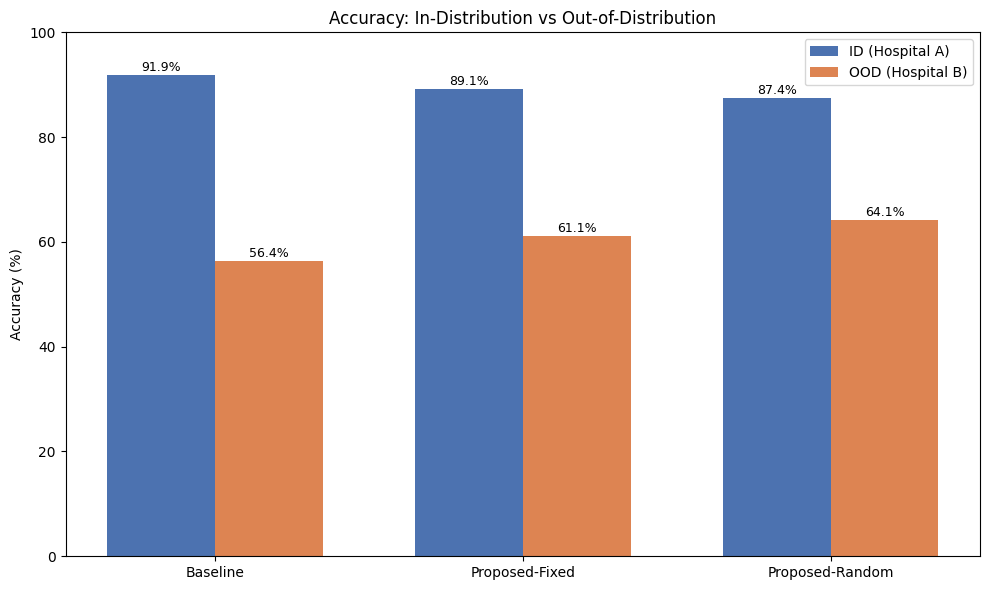

Saved: fig3_bar.png


In [13]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Baseline", "Proposed-Fixed", "Proposed-Random"]
id_acc  = [91.9, 89.1, 87.4]
ood_acc = [56.4, 61.1, 64.1]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, id_acc, width, label="ID (Hospital A)", color="#4C72B0")
bars2 = ax.bar(x + width/2, ood_acc, width, label="OOD (Hospital B)", color="#DD8452")

ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy: In-Distribution vs Out-of-Distribution")
ax.set_xticks(x); ax.set_xticklabels(models)
ax.legend()
ax.set_ylim(0, 100)

for bars in (bars1, bars2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("fig3_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig3_bar.png")